<a href="https://colab.research.google.com/github/batrisyiasuh/batrisyia5842342-AnalyticsEngineering/blob/main/Week8a_Modelling_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workshop 8a · Demo: Modelling

**Author:** Nursen Aydin

A telecommunication company wants to predict which customers will leave (*churn*) so that it can contact them in time. We build two models from the lecture, a *support vector machine (SVM)* and a *decision tree*, and check how well each works on customers it has never seen. The dataset is discussed in [Data Science for Business](http://data-science-for-biz.com/) (pages 73–79, Chapter 3).

Let's define the business problem and analytics problem:

*Business problem:* when customers leave for another provider, the company loses their monthly payments, and winning a new customer usually costs more than keeping an existing one. The company wants to keep more of its customers by contacting those who are likely to leave *before* they go, for example with a discount or a better plan.

*Analytics problem:* for each current customer, predict whether they will leave (`CLASS` = 1) or stay (`CLASS` = 0), using the information the company has about them at that moment, such as their income, average overcharge, leftover minutes, handset price and reported satisfaction. Because the answer is a category, this is a *classification* problem. The predictions tell the company which customers to contact.

In this demo we:
1. prepare and split the data;
2. build an SVM, see why *scaling* and the choice of *hyperparameters* (settings such as C) matter, and choose C with *cross-validation*;
3. build decision trees and choose their depth with *cross-validation*;
4. compare all models and decide which one we would use.

**Before you start:** put `churndata.csv` in the same folder as this notebook.

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

-----
## 1. Prepare and split the data

In [3]:
# Load the data and take a first look
churndt = pd.read_csv("churndata.csv")
print(churndt.shape)
churndt.head()

(11120, 15)


,id,COLLEGE,INCOME,AVG_OVERCHARGE,LEFTOVER,HOUSE,YEARS_AT_RESIDENCE,HANDSET_PRICE,OVER_15MINS_CALLS_PER_MONTH,AVG_CALL,REPORTED_SATISFACTION,REPORTED_USAGE_LEVEL,CONSIDERING_CHANGE_OF_PLAN,FAMILY_PLAN,CLASS
0,1,1,23306,43,0,299688,5,237,5,5,0,1,3,1,0
1,2,0,97528,163,45,973470,5,307,0,2,4,4,1,0,0
2,3,0,65328,0,0,438017,2,366,0,14,1,4,0,0,0
3,4,0,101357,71,13,251626,3,440,5,5,4,0,3,1,0
4,5,0,54546,102,58,163965,0,316,5,1,0,1,0,1,0


In [4]:
# Summary of the numerical columns
churndt.describe()

,id,COLLEGE,INCOME,AVG_OVERCHARGE,LEFTOVER,HOUSE,YEARS_AT_RESIDENCE,HANDSET_PRICE,OVER_15MINS_CALLS_PER_MONTH,AVG_CALL,REPORTED_SATISFACTION,REPORTED_USAGE_LEVEL,CONSIDERING_CHANGE_OF_PLAN,FAMILY_PLAN,CLASS
count,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000,11120.000000
mean,5560.500000,0.499910,80230.429406,85.372932,23.977428,496267.979946,2.525000,387.812500,8.032464,5.993975,1.559712,1.820144,2.389029,0.508183,0.493076
std,3210.211831,0.500022,41698.823420,85.793396,26.768740,253178.369553,1.709842,212.574309,8.974453,4.402991,1.628075,1.510829,1.462948,0.499956,0.499975
min,1.000000,0.000000,20007.000000,0.000000,0.000000,150027.000000,0.000000,130.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2780.750000,0.000000,42137.500000,0.000000,0.000000,265611.000000,1.000000,220.000000,1.000000,2.000000,0.000000,1.000000,1.000000,0.000000,0.000000
50%,5560.500000,0.000000,75218.500000,59.000000,15.000000,455928.500000,3.000000,325.000000,4.000000,5.000000,1.000000,1.000000,3.000000,1.000000,0.000000
75%,8340.250000,1.000000,115479.250000,179.000000,41.000000,707854.000000,4.000000,525.250000,15.000000,10.000000,4.000000,4.000000,3.000000,1.000000,1.000000
max,11120.000000,1.000000,159983.000000,335.000000,89.000000,999996.000000,5.000000,899.000000,29.000000,15.000000,4.000000,4.000000,4.000000,1.000000,1.000000


**CLASS** is the target variable: 1 = the customer left (churn), 0 = stayed. The column **id** is a customer number: an identifier, not a quantity.

In [5]:
# Remove the identifier
churndt = churndt.drop(columns=["id"])

# Share of churners
print(churndt["CLASS"].value_counts(normalize=True).round(3))

CLASS
0    0.507
1    0.493
Name: proportion, dtype: float64


About half of the customers churn (49%) and about half stay (51%).

We split the data into a training set (70%) and a test set (30%), stratified by CLASS.

In [6]:
X = churndt.drop(columns=["CLASS"])
y = churndt["CLASS"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11, stratify=y)

print("Training set:", X_train.shape, " Test set:", X_test.shape)

Training set: (7784, 13)  Test set: (3336, 13)


-----
## 2. Support vector machine (SVM)

### What is an SVM?

An SVM draws a **boundary** between the two classes (here: churners and stayers) and places it so that the **margin**, the empty space between the boundary and the nearest customers of each class, is as **wide** as possible. A wide margin makes the model less sensitive to small changes in the data. The customers closest to the boundary, which decide where it goes, are called **support vectors**.

| Strengths | Weaknesses |
|---|---|
| Often very accurate, also with many features | Hard to explain: no simple rules to show a manager |
| Flexible boundaries with the RBF kernel | Needs **scaling** and careful choice of settings (e.g. hyperparameter C) |
| Works well on small and medium-sized datasets | Slow on large datasets: training time grows quickly with the number of rows |

### Linear or RBF kernel?

The **kernel** decides the shape of the boundary.

| | `kernel="linear"` | `kernel="rbf"` (radial basis function) |
|---|---|---|
| Shape of the boundary | A straight line (a flat surface with many features) | A curved, flexible boundary |
| Good when… | the classes can be separated reasonably well by a straight boundary; there are **many features** compared with the number of rows | the relationship is **curved** or involves combinations of features |
| Speed | Faster | Slower on large data |
| Risk | Too simple if the real boundary is curved (underfitting) | Can follow the training data too closely (overfitting) if C is too large |

**A practical approach:** start with a linear kernel as a simple reference, then try RBF, and compare them on data the model has not seen. If RBF is not clearly better, prefer the simpler linear model.

*Note:* the RBF kernel has a second setting, `gamma`, which controls how "wiggly" the boundary can be. The default (`gamma="scale"`) works well in most cases, so we leave it as it is.

### In scikit-learn

`SVC()` builds an SVM for classification. It looks for the boundary that separates churners from stayers with the **widest margin**:

```python
svm_model = SVC(kernel="rbf", C=1.0)
svm_model.fit(X_train, y_train)
```

- `kernel` sets the shape of the boundary: `"linear"` for a straight boundary, `"rbf"` (radial basis function) for a flexible, curved one.
- `C` is a hyperparameter and it sets how much the model is penalised for misclassifying training customers (default 1.0). More on this below.

### Scaling

An SVM measures **distances** between customers. Our features have very different ranges: HOUSE goes up to about 1,000,000, while COLLEGE is 0 or 1. Without scaling, HOUSE would dominate every distance, and the other features would hardly count.

`StandardScaler()` rescales each feature to mean 0 and standard deviation 1:

```python
scaler = StandardScaler()
# learn the mean and standard deviation from dataset1, then scale dataset1
scaled_data1 = scaler.fit_transform(dataset1)   

# scale dataset2 with the mean and standard deviation learned from dataset1
scaled_data2 = scaler.transform(dataset2)      
```

**Question:** the mean and the standard deviation are **calculated from the data**. Which of our sets should be `dataset1`, and which `dataset2`? Why?

*Your answer:*

In [8]:
# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build an SVM with an RBF kernel and C = 1
svm_model = SVC(kernel="rbf", C=1.0)
svm_model.fit(X_train_scaled, y_train)


SVC()

`.predict()` gives the predicted class of each customer. Let's look at the first ten test customers: their original values, what really happened (`CLASS`) and the SVM's prediction (`Predicted`):

In [9]:
svm_predict = svm_model.predict(X_test)

# The first ten test customers: original values, what really happened and the prediction
compare = X_test.head(10).copy()
compare["CLASS"] = y_test.values[:10]
compare["Predicted"] = svm_predict[:10]
compare

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,COLLEGE,INCOME,AVG_OVERCHARGE,LEFTOVER,HOUSE,YEARS_AT_RESIDENCE,HANDSET_PRICE,OVER_15MINS_CALLS_PER_MONTH,AVG_CALL,REPORTED_SATISFACTION,REPORTED_USAGE_LEVEL,CONSIDERING_CHANGE_OF_PLAN,FAMILY_PLAN,CLASS,Predicted
5705,0,31135,59,0,757427,2,245,4,9,2,1,1,0,0,1
5661,0,83662,179,0,195870,2,397,14,8,0,0,3,1,1,1
1205,1,91368,167,88,340659,1,351,19,2,4,1,4,1,1,1
8331,0,154060,247,0,787149,4,385,0,2,4,4,3,0,1,1
10529,0,73079,0,12,191682,1,325,1,4,4,1,3,1,0,1
894,0,41885,0,85,154009,2,343,1,1,4,2,3,0,0,1
3716,1,35710,281,0,291307,5,760,19,14,0,4,0,1,1,1
8369,0,44777,175,0,582428,2,212,20,9,0,4,1,1,1,1
6593,0,94237,0,49,258017,1,334,0,2,0,4,4,1,0,1
6810,1,126162,0,15,558645,1,403,1,2,0,1,1,0,1,1


Note that the SVM did not use the original X_test for prediction. It predicts with the *scaled* values. We print the original values just for demonstration (to explain what prediction means in practice).

### How is accuracy measured?

**Accuracy** is the share of customers whose class the model predicts correctly:

Accuracy = number of correct predictions / total number of customers in the prediction set

Look at the ten rows above: in how many does the prediction match CLASS? Let's count it for all test customers. `svm_predict == y_test` is True where the prediction is correct.

In [10]:
# Accuracy "by hand"
correct = (svm_predict == y_test).sum()   # number of correct predictions
total = len(y_test)                       # total number of customers in the test set

print(f"Correct predictions: {correct} of {total}")
print(f"Accuracy by hand:    {correct / total:.3f}")

# The same with .score(): it predicts and compares in one step
print(f"\nTraining accuracy: {svm_model.score(X_train_scaled, y_train):.3f}")
print(f"Test accuracy:     {svm_model.score(X_test_scaled,y_test):.3f}")

Correct predictions: 1645 of 3336
Accuracy by hand:    0.493

Training accuracy: 0.721
Test accuracy:     0.670


`.score()` needs the **features** and the **true classes** of the same set: it predicts the class of each customer, compares with the true class and returns the share of correct predictions. Training accuracy shows how well the model fits the data it learned from; **test accuracy** shows how well it works on new customers, which is what we care about.

### Is this a good accuracy? The baseline

An accuracy on its own does not tell us much: we need something to compare it with. The simplest reference is a *baseline*: the accuracy we would get *without any model*, by predicting the most common class for every customer.

Here slightly more customers stay than leave, so the baseline predicts *stay* for everyone. It is right for every customer who really stayed, so its accuracy is simply the share of stayers in the test set. A useful model must do clearly better than this.

*Why this matters:* imagine that 95% of the customers stayed. A "model" that predicts *stay* for everyone would reach 95% accuracy without finding a single churner. Without a baseline, 95% would look excellent.

In [11]:
# Baseline: predict "stay" (0) for every customer in the test set
# y_test == 0 is True for every customer who stayed; .mean() gives the share of True values
baseline = (y_test == 0).mean()

print(f"Baseline (predict that nobody churns): {baseline:.3f}")
print(f"SVM test accuracy:                     {svm_model.score(X_test_scaled, y_test):.3f}")

Baseline (predict that nobody churns): 0.507
SVM test accuracy:                     0.670


The SVM is right for about *67%* of the test customers, against about *51%* for the baseline, so it is clearly better than predicting without a model. From now on, we compare every model with this baseline.

### What if we forget to scale?

Same model, same data, but **without** scaling:

In [12]:
svm_unscaled = SVC(kernel="rbf", C=1.0)
svm_unscaled.fit(X_train,y_train)

print(f"Test accuracy without scaling: {svm_unscaled.score(X_test, y_test):.3f}")

Test accuracy without scaling: 0.603


Without scaling, the test accuracy drops by about *7 percentage points*. Nothing warns us: the code runs perfectly. This is a typical mistake to check for in any SVM code, including code written by an AI assistant.

### The hyperparameter setting (C)

`C` is the price the SVM pays for each misclassified *training* customer:
- **small C**: mistakes are cheap, so the model keeps a wide margin and a simple boundary;
- **large C**: mistakes are expensive, so the model bends its boundary to get almost every training customer right.

Which value of C should we use? We must not choose it by looking at the test set: the test set is kept for the final check. Instead we use **5-fold cross-validation** on the training set, as in the lecture: the training set is cut into 5 parts, the SVM is trained on 4 parts and checked on the 5th, five times, and the 5 accuracies are averaged into the *cross-validated accuracy*.

One more detail: in every round, the scaler must learn the mean and standard deviation from the 4 training parts only. A **pipeline** does this for us: `make_pipeline()` joins the scaler and the SVM into one model, so we give it the *unscaled* data.

```python
# scaling + SVM in one model
model_pipeline = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0))   

# 5 accuracies, one per round
scores = cross_val_score(model_pipeline, features, target, cv=5)            

# the cross-validated accuracy
scores.mean()                                                        
```

Let's try three values of C. (This takes about a minute: an SVM with a large C needs longer to train.)

In [13]:
for C in [0.01, 1, 100]:
    svm_pipeline = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C))   # scaling + SVM in one model
    cv_acc = cross_val_score(svm_pipeline, X_train,y_train, cv=5).mean()            # cross-validated accuracy
    train_acc = svm_pipeline.fit(X_train, y_train).score(X_train, y_train)     # accuracy on the data it learned from
    print(f"C = {C:6}: training accuracy {train_acc:.3f}, cross-validated accuracy {cv_acc:.3f}")

C =   0.01: training accuracy 0.645, cross-validated accuracy 0.641
C =      1: training accuracy 0.721, cross-validated accuracy 0.672
C =    100: training accuracy 0.914, cross-validated accuracy 0.617


**Question:** what happens to the training accuracy and the cross-validated accuracy as C grows? Which C would you choose?

*Your answer:*

-----
## 3. Decision trees

### What is a decision tree?

A decision tree asks a series of **yes/no questions** about the features ("Is the house value below 600,000?", "Is the overcharge above 98?"). Each answer leads to the next question, until we reach a **leaf** that gives the prediction. At each step, the tree chooses the question that separates the classes best (with `criterion="entropy"`, the question with the highest information gain, as in Workshop 2).

| Strengths | Weaknesses |
|---|---|
| **Easy to explain**: a small tree is a set of rules a manager can read and check | **Overfits** easily if it is allowed to grow without limits |
| **No scaling needed**: each question looks at one feature at a time | **Unstable**: a small change in the data can give a quite different tree |
| Finds combinations of features automatically (e.g. cheap house *and* high overcharge) | May need many splits to capture complex relationships in the data, producing a large tree that is harder to interpret. |

**Good when** explanation matters (credit decisions, HR, medicine), when features have very different scales or mix numbers and categories, and as a first model to understand the data.

**Key setting:** `max_depth`, the maximum number of splitting levels in the tree. A small depth gives a simple tree that may miss patterns (underfitting); a large depth gives a complex tree that learns the training data by heart (overfitting). Other settings with a similar role are `min_samples_leaf` (the smallest number of customers allowed in a leaf) and `max_leaf_nodes`.

*Looking ahead:* trees are unstable on their own, but combining many trees (**random forests** and **gradient boosting**) gives some of the most accurate models in practice. This comes later in the module.

### A tree without limits

A tree **without limits** keeps splitting until every leaf is pure:

In [14]:
full_tree = DecisionTreeClassifier(criterion="entropy", random_state=11)
full_tree.fit(X_train, y_train)

print(f"Depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}")
print(f"Training accuracy: {full_tree.score(X_train, y_train):.3f}")
print(f"Test accuracy:     {full_tree.score(X_test, y_test):.3f}")

Depth: 31, leaves: 1610
Training accuracy: 1.000
Test accuracy:     0.612


A perfect score on the training customers, but it performs noticeably worse than the SVM on new customers. With more than 1,600 leaves, it appears to have fitted the training data too closely which is an indication of overfitting. As in Workshop 2, let's limit the depth. To choose the depth without using the test set, we again use 5-fold cross-validation on the training set, and compare the training and the cross-validated accuracy for depths 1 to 20. (A tree needs no scaling, so we do not need a pipeline here.)

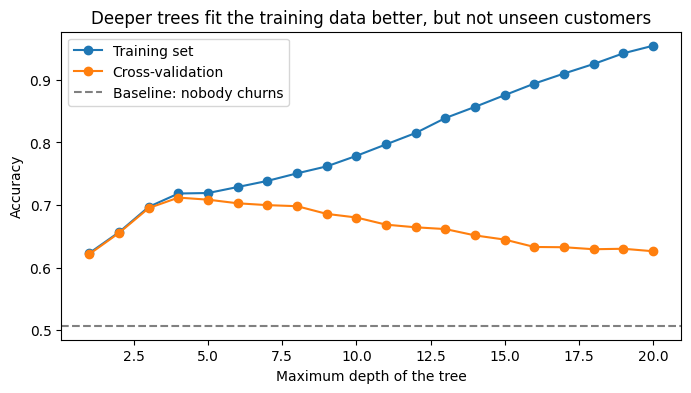

depth  1: training 0.623, cross-validated 0.622
depth  2: training 0.657, cross-validated 0.655
depth  3: training 0.697, cross-validated 0.695
depth  4: training 0.718, cross-validated 0.712
depth  5: training 0.719, cross-validated 0.709
depth  6: training 0.729, cross-validated 0.703
depth  7: training 0.739, cross-validated 0.700
depth  8: training 0.751, cross-validated 0.698
depth  9: training 0.762, cross-validated 0.686
depth 10: training 0.779, cross-validated 0.680
depth 11: training 0.797, cross-validated 0.669
depth 12: training 0.815, cross-validated 0.664
depth 13: training 0.839, cross-validated 0.661
depth 14: training 0.857, cross-validated 0.651
depth 15: training 0.876, cross-validated 0.645
depth 16: training 0.894, cross-validated 0.633
depth 17: training 0.910, cross-validated 0.632
depth 18: training 0.926, cross-validated 0.629
depth 19: training 0.943, cross-validated 0.630
depth 20: training 0.955, cross-validated 0.626


In [17]:
depths = range(1, 21)
train_acc, cv_acc = [], []
for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=11)
    cv_acc.append(cross_val_score(model, X_train, y_train, cv=5).mean())   # cross-validated accuracy
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))                             # training accuracy

plt.figure(figsize=(8, 4))
plt.plot(depths, train_acc, marker="o", label="Training set")
plt.plot(depths, cv_acc, marker="o", label="Cross-validation")
plt.axhline(baseline, color="grey", linestyle="--", label="Baseline: nobody churns")
plt.xlabel("Maximum depth of the tree")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Deeper trees fit the training data better, but not unseen customers")
plt.show()

for d, tr, cv in zip(depths, train_acc, cv_acc):
    print(f"depth {d:2d}: training {tr:.3f}, cross-validated {cv:.3f}")

**Question:** which depth would you choose, and why?

*Your answer:*

*Note:* we chose C and the depth with cross-validation on the training set, so the test set has not been used to choose anything. We use it to compare the final models in Section 4.

Let's look inside the tree of the chosen depth:

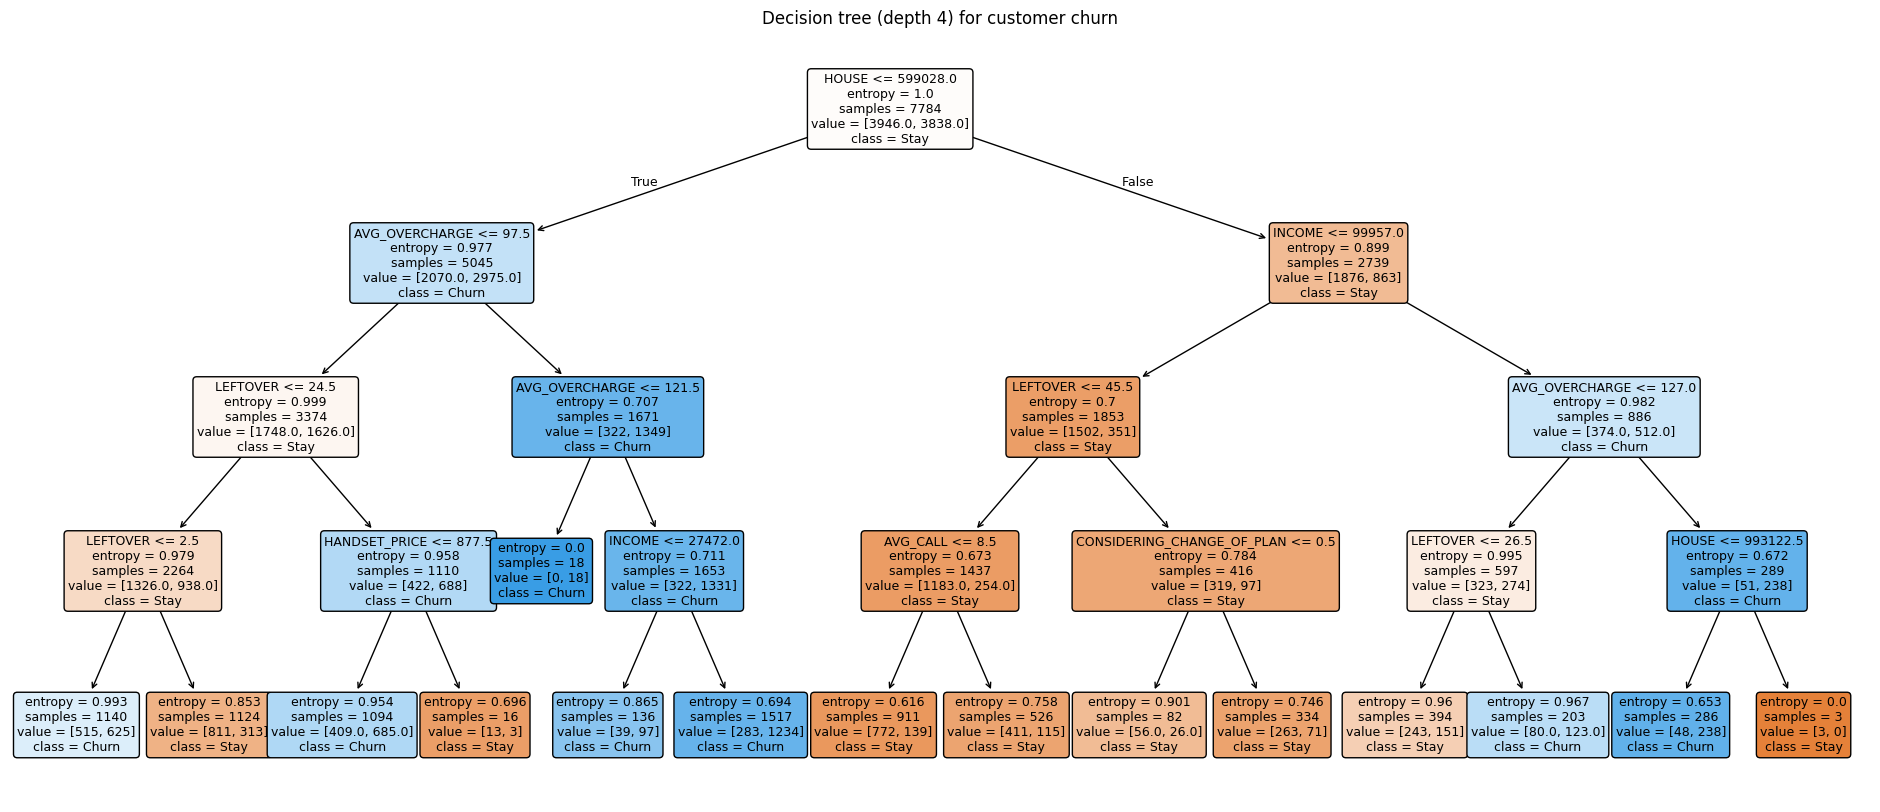

Test accuracy: 0.691


In [19]:
chosen_tree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=11)
chosen_tree.fit(X_train, y_train)

plt.figure(figsize=(24, 10))
plot_tree(chosen_tree, feature_names=X_train.columns, class_names=["Stay", "Churn"], filled=True, rounded=True, fontsize=9)
plt.title(f"Decision tree (depth {chosen_tree.get_depth()}) for customer churn")
plt.show()

print(f"Test accuracy: {chosen_tree.score(X_test, y_test):.3f}")

**Question:** follow the path to one "Churn" leaf. Describe in words which customers the tree expects to leave.

*Your answer:*

-----
## 4. Which model would you use?

Choosing a model involves predictive performance, interpretability and computational cost:

| | SVM | Decision tree |
|---|---|---|
| Explanation | Less straightforward, especially with RBF | Easy to explain when the tree is small |
| Scaling needed? | Usually recommended | Not needed |
| Main setting | C (and the kernel) | max_depth |
| Predictive performance | A linear model may be too simple; an RBF model may overfit if poorly tuned | A very small tree may miss patterns; a deep tree may fit the training data too closely |
| Large datasets | Slow | Fast |

In [20]:
results = pd.DataFrame({
    "Model": ["Baseline: nobody churns", "SVM without scaling", "SVM, scaled, C = 1 (chosen)", "SVM, scaled, C = 100",
              "Tree without limits", "Tree, chosen depth"],
    "Test accuracy": [baseline,
                      svm_unscaled.score(X_test, y_test),
                      svm_model.score(X_test_scaled, y_test),
                      SVC(kernel="rbf", C=100).fit(X_train_scaled, y_train).score(X_test_scaled, y_test),
                      full_tree.score(X_test, y_test),
                      chosen_tree.score(X_test, y_test)],
}).round(3)
results

,Model,Test accuracy
0,Baseline: nobody churns,0.507
1,SVM without scaling,0.603
2,"SVM, scaled, C = 1 (chosen)",0.670
3,"SVM, scaled, C = 100",0.615
4,Tree without limits,0.612
5,"Tree, chosen depth",0.691


**Question:** which model would you recommend to the company, and why? Think about accuracy, but also about how easy it is to explain.

*Your answer:*

-----
## Summary

1. **Scaling** matters for an SVM: without it, the test accuracy fell by about 7 points.
2. **C** controls how closely an SVM follows the training data. A very large C overfits.
3. A tree **without limits** learns the training data by heart. Limiting the **depth** gives a simpler tree that does better on new customers.
4. We choose settings such as C and the depth with **cross-validation** on the training set. A **pipeline** makes sure the scaler is fitted inside each round.
5. We compare the final models on the **test set** and against a **baseline**, and we also consider how easy each model is to explain.